# Data Exploration
**Where to run:** Kaggle Notebooks is easiest (attach the competition data, free GPU: Settings > Accelerator > GPU). Colab also works if you upload the data (see the Colab note in the data cell).

## 1. Import the dataset

In [2]:
# Install only if missing (timm gives easy access to pretrained models later)
import importlib, subprocess, sys
for pkg in ["timm", "scikit-learn"]:
    try:
        importlib.import_module(pkg.replace("scikit-learn", "sklearn"))
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

In [3]:
import random, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, "| torch", torch.__version__)

Device: cpu | torch 2.14.0+cpu


## 2. Locate the data


In [4]:
DATA_DIR = Path(".")
TRAIN_DIR = DATA_DIR / "train" / "train"
TEST_DIR = DATA_DIR / "test" / "test"
print("DATA_DIR:", DATA_DIR.resolve())
print("train files:", len(list(TRAIN_DIR.iterdir())))
print("test files: ", len(list(TEST_DIR.iterdir())))
print([p.name for p in TRAIN_DIR.iterdir()][:3])

DATA_DIR: C:\Users\yzsha\Documents\DataAndAI_project\KaggleCompetitionProject\KaggleCompetitionENGE707
train files: 63660
test files:  29443
['00001.jpg', '00002.jpg', '00003.jpg']


## 3. Load the files

In [5]:
# IMPORTANT: read ids as strings so '00001' keeps its leading zeros
train_df = pd.read_csv(DATA_DIR / "train_labels.csv", dtype={"image_id": str})
sample_sub = pd.read_csv(DATA_DIR / "sample_submission.csv", dtype={"image_id": str})
print(train_df.shape, sample_sub.shape)
display(train_df.head())

# Use the exact class spellings from the data (brief says both CatEye and CatEyes)
CLASSES = sorted(train_df["class"].unique())
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
IDX_TO_CLASS = {i: c for c, i in CLASS_TO_IDX.items()}
print(CLASS_TO_IDX)
print("Sample submission classes:", sorted(sample_sub["class"].unique()))

(63660, 2) (29443, 2)


,image_id,class
0,00001,DogEye
1,00002,DogMouth
2,00003,DogFace
3,00004,DogNose
4,00005,DogNose


{'CatEye': 0, 'CatFace': 1, 'CatMouth': 2, 'CatNose': 3, 'DogEye': 4, 'DogFace': 5, 'DogMouth': 6, 'DogNose': 7}
Sample submission classes: ['CatEye', 'CatFace', 'CatMouth', 'CatNose', 'DogEye', 'DogFace', 'DogMouth', 'DogNose']


## 4. Map the csv file to the image

In [6]:
# Map image_id -> file path, matching on the integer value of the id
# (sample_submission ids are unpadded, e.g. '1', but filenames are padded, e.g. '00001.jpg')
def build_path_map(folder):
    return {int(p.stem): p for p in folder.iterdir() if p.is_file()}

train_map, test_map = build_path_map(TRAIN_DIR), build_path_map(TEST_DIR)
train_df["path"] = train_df["image_id"].astype(int).map(train_map)
sample_sub["path"] = sample_sub["image_id"].astype(int).map(test_map)
print("Missing train files:", train_df["path"].isna().sum())
print("Missing test files: ", sample_sub["path"].isna().sum())
train_df["label"] = train_df["class"].map(CLASS_TO_IDX)

Missing train files: 0
Missing test files:  0


## 5. Structure of Data

In [7]:
# --- Structure of the training data ---
print("Train rows, columns:", train_df[["image_id", "class"]].shape)
print("Column dtypes:", train_df[["image_id", "class"]].dtypes.astype(str).to_dict())
print("Null values:", train_df[["image_id", "class"]].isna().sum().to_dict())
print("Duplicate ids in CSV:", train_df["image_id"].duplicated().sum())
print("Train id range:", train_df["image_id"].astype(int).min(), "-", train_df["image_id"].astype(int).max())
print("Train file types:", pd.Series([p.suffix.lower() for p in train_map.values()]).value_counts().to_dict())

# --- Structure of the test data ---
print("\nTest rows, columns:", sample_sub[["image_id", "class"]].shape)
print("Duplicate ids in sample_submission:", sample_sub["image_id"].duplicated().sum())
print("Test id range:", sample_sub["image_id"].astype(int).min(), "-", sample_sub["image_id"].astype(int).max())
print("Test file types:", pd.Series([p.suffix.lower() for p in test_map.values()]).value_counts().to_dict())
print("Test classes in sample_submission:", sample_sub["class"].value_counts().to_dict())

# Are the two sets kept separate? (same numbers are reused, but in different folders)
print("\nTrain files:", len(train_map), "| Test files:", len(test_map))
display(sample_sub[["image_id", "class"]].head())

Train rows, columns: (63660, 2)
Column dtypes: {'image_id': 'str', 'class': 'str'}
Null values: {'image_id': 0, 'class': 0}
Duplicate ids in CSV: 0
Train id range: 1 - 63660
Train file types: {'.jpg': 63660}

Test rows, columns: (29443, 2)
Duplicate ids in sample_submission: 0
Test id range: 1 - 29443
Test file types: {'.jpg': 29443}
Test classes in sample_submission: {'CatEye': 4567, 'DogEye': 4221, 'CatFace': 3571, 'CatMouth': 3570, 'CatNose': 3457, 'DogFace': 3407, 'DogMouth': 3341, 'DogNose': 3309}

Train files: 63660 | Test files: 29443


,image_id,class
0,1,DogEye
1,2,CatNose
2,3,CatNose
3,4,DogFace
4,5,DogMouth


## 6. Number of instances in each class

In [8]:
# --- Number of training instances in each class ---
class_counts = train_df["class"].value_counts().reindex(CLASSES, fill_value=0)
class_counts = class_counts.rename_axis("class").reset_index(name="instances")
display(class_counts)
print("Total training instances:", class_counts["instances"].sum())

,class,instances
0,CatEye,13884
1,CatFace,6942
2,CatMouth,6942
3,CatNose,6942
4,DogEye,11580
5,DogFace,5790
6,DogMouth,5790
7,DogNose,5790


Total training instances: 63660


## 7. Demonstration of each Image in each Class

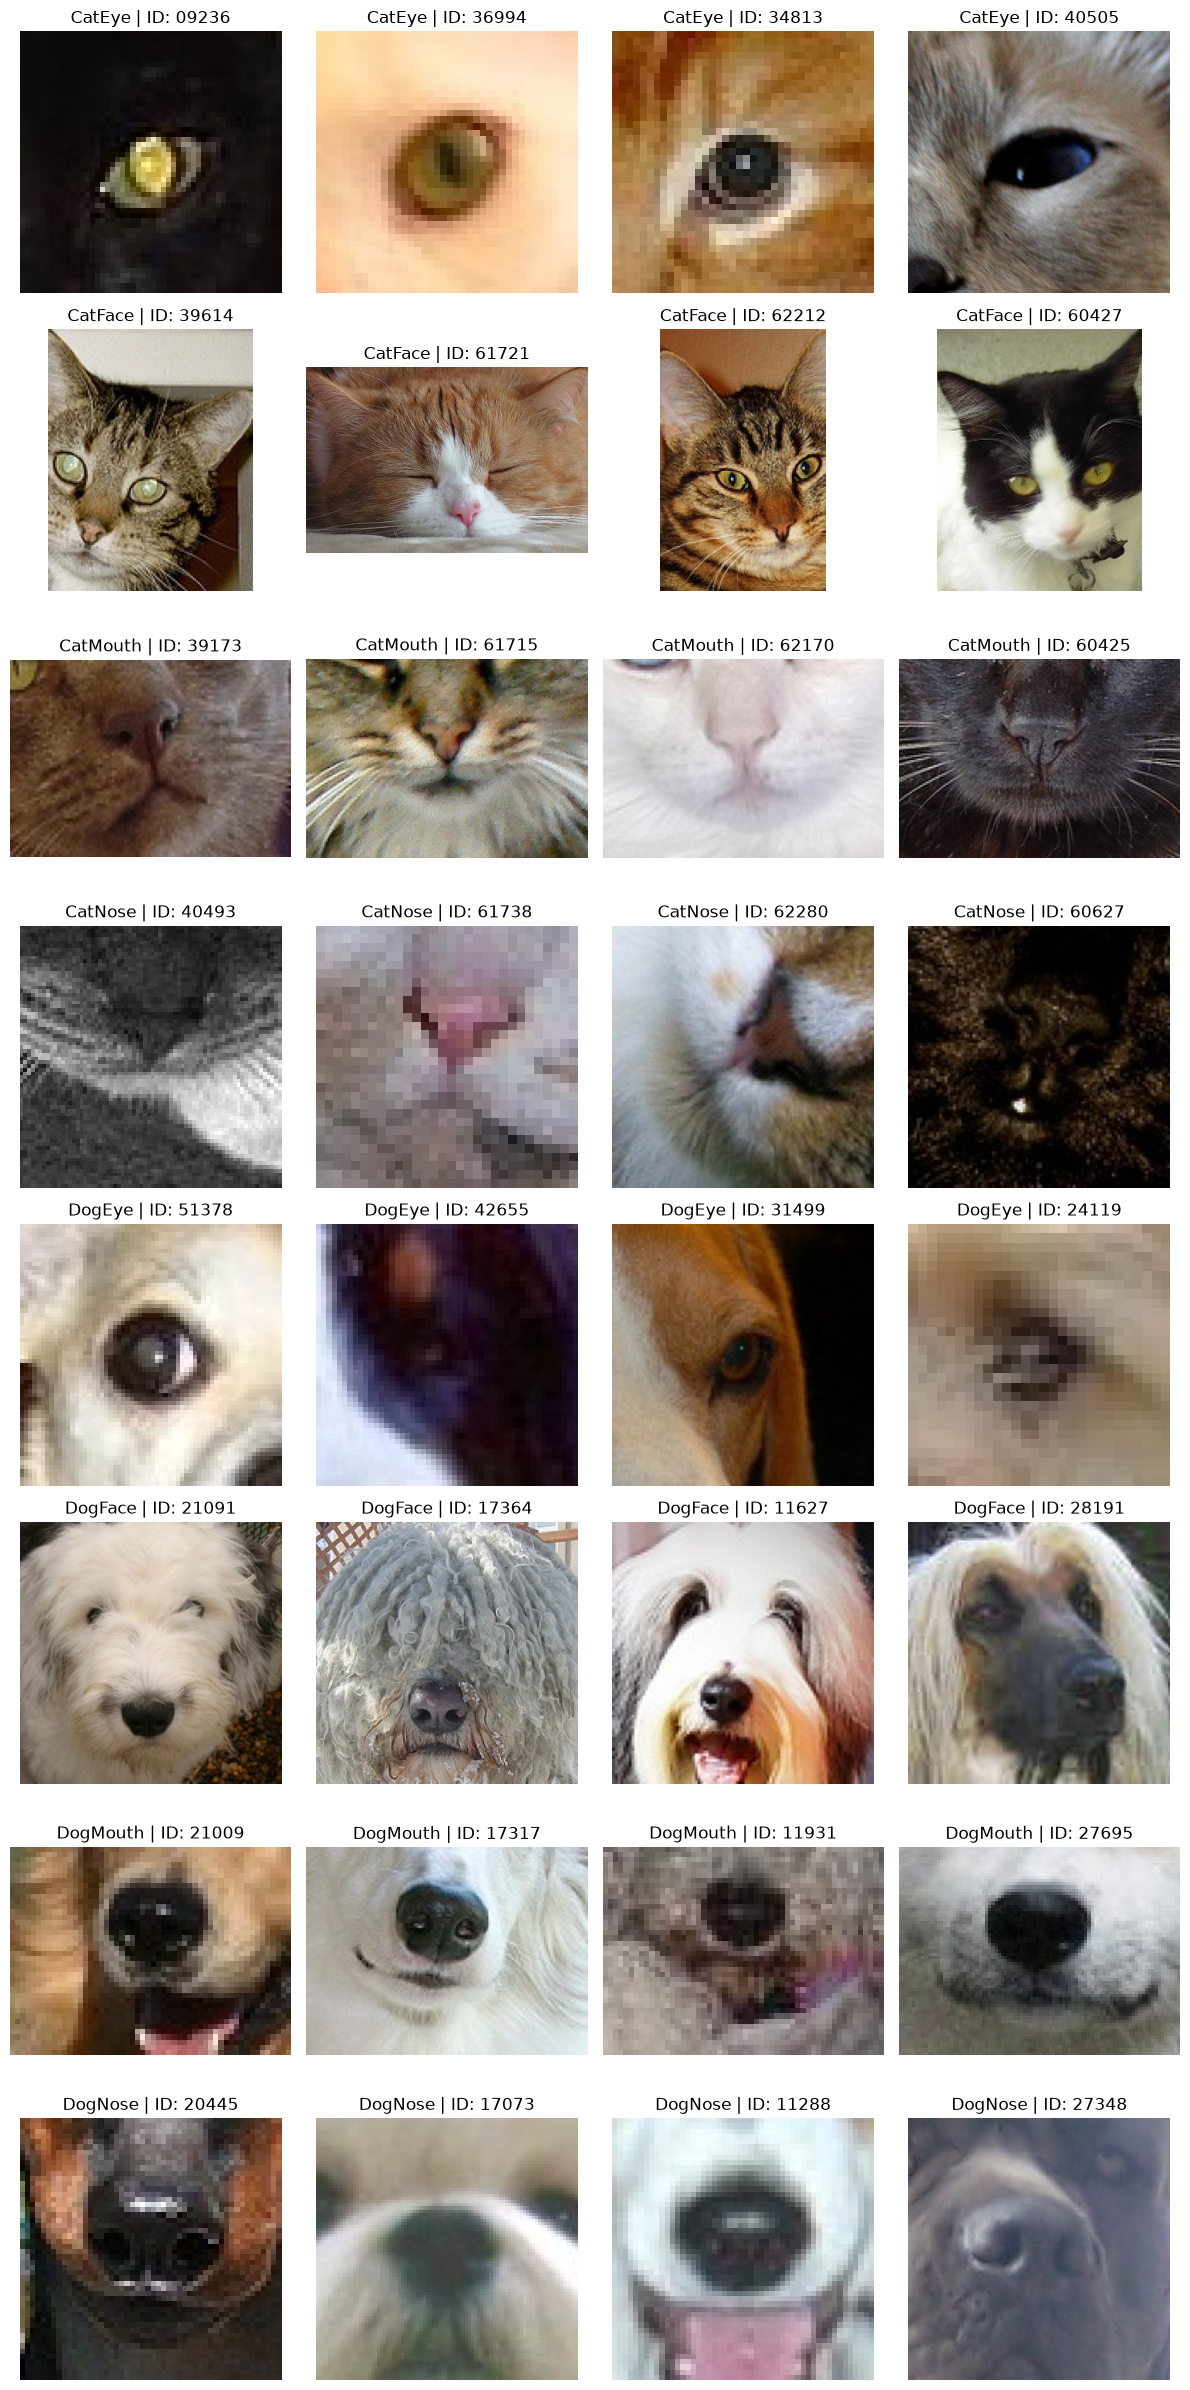

In [11]:
# Show four different training images from each class
N_IMAGES = 4
fig, axes = plt.subplots(
    len(CLASSES), N_IMAGES,
    figsize=(12, 3 * len(CLASSES)), squeeze=False
)

for row, class_name in enumerate(CLASSES):
    samples = train_df[train_df["class"] == class_name].sample(
        n=N_IMAGES, random_state=SEED
    )
    for col, (_, sample) in enumerate(samples.iterrows()):
        ax = axes[row, col]
        with Image.open(sample["path"]) as image:
            ax.imshow(image.convert("RGB"))
        ax.set_title(f"{class_name} | ID: {sample['image_id']}")
        ax.axis("off")

plt.tight_layout()
plt.show()

## 8. Checking Image Dimension

In [13]:
import hashlib
import io

# --- Inspect training and test images ---
records = []

for split, dataframe in [("train", train_df), ("test", sample_sub)]:
    for _, sample in dataframe.iterrows():
        record = {
            "split": split,
            "image_id": sample["image_id"],
            "class": sample["class"] if split == "train" else None,
            "path": str(sample["path"]),
            "width": None,
            "height": None,
            "sha256": None,
            "error": None,
        }

        try:
            image_bytes = Path(sample["path"]).read_bytes()
            record["sha256"] = hashlib.sha256(image_bytes).hexdigest()

            with Image.open(io.BytesIO(image_bytes)) as image:
                image.load()
                record["width"], record["height"] = image.size

        except Exception as error:
            record["error"] = f"{type(error).__name__}: {error}"

        records.append(record)

    print(f"Checked {split}: {len(dataframe):,} images")

image_checks = pd.DataFrame(records)
image_checks[["width", "height"]] = (
    image_checks[["width", "height"]].astype("Int64")
)
valid_images = image_checks[image_checks["error"].isna()].copy()

# --- Count each image size ---
size_counts = (
    valid_images.groupby(["split", "width", "height"])
    .size()
    .reset_index(name="instances")
    .sort_values(["split", "instances"], ascending=[True, False])
)

print("\nImage size frequencies:")
display(size_counts)

print("\nDimension summary:")
display(
    valid_images.groupby("split")[["width", "height"]]
    .agg(["min", "median", "max"])
)

# Flag sizes that differ from the most common size in each dataset
for split in ["train", "test"]:
    counts = size_counts[size_counts["split"] == split]
    if counts.empty:
        continue

    common_size = counts.iloc[0]
    different_sizes = valid_images[
        (valid_images["split"] == split)
        & (
            (valid_images["width"] != common_size["width"])
            | (valid_images["height"] != common_size["height"])
        )
    ]

    print(
        f"\n{split}: {len(different_sizes):,} images differ from "
        f"the most common size "
        f"({common_size['width']} × {common_size['height']})."
    )
    display(different_sizes[["image_id", "width", "height"]].head(20))

Checked train: 63,660 images
Checked test: 29,443 images

Image size frequencies:


,split,width,height,instances
379,test,40,40,503
640,test,50,50,402
1581,test,80,80,370
181,test,30,30,349
924,test,60,60,343
...,...,...,...,...
15642,train,1786,1787,1
15643,train,1791,1736,1
15644,train,1873,1873,1
15645,train,2190,2070,1



Dimension summary:


width              height             
        min median   max    min median   max
split                                       
test      8   82.0  1832      9   80.0  1978
train     4   84.0  2219      4   80.0  2219


train: 62,598 images differ from the most common size (40 × 40).


,image_id,width,height
0,00001,36,36
1,00002,214,157
2,00003,97,97
3,00004,110,110
4,00005,42,42
5,00006,28,28
6,00007,182,135
7,00008,128,128
8,00009,343,376
9,00010,36,36



test: 28,940 images differ from the most common size (40 × 40).


,image_id,width,height
63660,1,112,112
63661,2,96,69
63662,3,34,34
63663,4,119,119
63664,5,210,140
63665,6,64,58
63666,7,133,98
63667,8,224,192
63668,9,92,91
63669,10,60,60


## 9. Checking Corrupted files


In [15]:
# Display files that could not be read or fully decoded
corrupted_files = image_checks[image_checks["error"].notna()].copy()

print(f"Unreadable or corrupted files: {len(corrupted_files):,}")
display(
    corrupted_files[["split", "image_id", "path", "error"]]
)

Unreadable or corrupted files: 0


,split,image_id,path,error


## Dupplicate image check

Checking whether there is duplicate images but using sha256. This does not check resized or recompressed copies.

In [ ]:
# Exact duplicates based on file contents
hashed_images = image_checks.dropna(subset=["sha256"])

duplicate_images = hashed_images[
    hashed_images.duplicated("sha256", keep=False)
].sort_values(["sha256", "split", "image_id"]).copy()

duplicate_groups = duplicate_images["sha256"].nunique()

print(f"Exact duplicate groups: {duplicate_groups:,}")
print(f"Files in duplicate groups: {len(duplicate_images):,}")
print(f"Extra copies: {len(duplicate_images) - duplicate_groups:,}")

display(
    duplicate_images[["sha256", "split", "image_id", "class", "path"]]
)

# Check for identical files shared between train and test
split_counts = hashed_images.groupby("sha256")["split"].nunique()
shared_hashes = split_counts[split_counts > 1].index

cross_split_duplicates = duplicate_images[
    duplicate_images["sha256"].isin(shared_hashes)
]

print(f"\nDuplicate groups shared between train and test: {len(shared_hashes):,}")
display(
    cross_split_duplicates[["sha256", "split", "image_id", "path"]]
)